In [3]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("FlowCast - Traffic Volume Forecasting")
print("Libraries imported successfully!")

FlowCast - Traffic Volume Forecasting
Libraries imported successfully!


In [4]:
model_path = "../models/traffic_volume_random_forest.pkl"
features_path = "../models/traffic_volume_features.json"
data_path = "../data/processed/flowcast_merged.csv"

for label, path in [
    ("Traffic model", model_path),
    ("Feature file", features_path),
    ("Processed dataset", data_path)
]:
    print(f"{label} exists: {os.path.exists(path)}")

Traffic model exists: True
Feature file exists: True
Processed dataset exists: True


In [5]:
# Load the trained model and its expected features

with open(features_path, "r") as f:
    model_features = json.load(f)

traffic_model = joblib.load(model_path)

print("Traffic model loaded successfully!")
print("Model type:", type(traffic_model).__name__)
print("Number of expected features:", len(model_features))
print("Expected features:")
print(model_features)

C:\Users\pathi\anaconda3\Lib\site-packages\sklearn\base.py:380: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeRegressor from version 1.7.2 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


Traffic model loaded successfully!
Model type: RandomForestRegressor
Number of expected features: 14
Expected features:
['traffic_volume_lag_1', 'traffic_volume_lag_2', 'traffic_volume_lag_4', 'avg_speed_lag_1', 'avg_speed_lag_2', 'traffic_volume_rolling_mean_4', 'avg_speed_rolling_mean_4', 'hour', 'minute', 'day_of_week', 'month', 'is_weekend', 'is_morning_peak', 'is_evening_peak']


C:\Users\pathi\anaconda3\Lib\site-packages\sklearn\base.py:380: InconsistentVersionWarning: Trying to unpickle estimator RandomForestRegressor from version 1.7.2 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [6]:
# Load the processed FlowCast dataset

df = pd.read_csv(data_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

C:\Users\pathi\AppData\Local\Temp\ipykernel_26364\1524472177.py:3: DtypeWarning: Columns (27,29) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_path)


Dataset loaded successfully!
Dataset shape: (176701, 31)

Column names:
['road_id', 'road_name', 'latitude', 'longitude', 'weather_station_id', 'date', 'time', 'traffic_volume', 'vehicle_count', 'vehicle_type_dist', 'avg_speed', 'occupancy', 'congestion_level', 'travel_time', 'accident_count', 'signal_timing', 'road_capacity', 'timestamp', 'capacity_30min', 'volume_capacity_ratio', 'date_weather', 'time_weather', 'weather_condition', 'temperature', 'rainfall', 'visibility', 'public_holiday', 'holiday_name', 'event_flag', 'event_name', 'roadwork_flag']

First 5 rows:


,road_id,road_name,latitude,longitude,weather_station_id,date,time,traffic_volume,vehicle_count,vehicle_type_dist,...,time_weather,weather_condition,temperature,rainfall,visibility,public_holiday,holiday_name,event_flag,event_name,roadwork_flag
0,NL-001,Northline Ave @ 5th,28.643422,77.190411,WS-NORTH,2025-01-01,00:00,97.0,97,"{""2W"": 0.39, ""Car"": 0.35, ""LCV"": 0.12, ""HCV"": ...",...,00:00,Clear,12.7,0.0,10000.0,1,New Year's Day,0,NaN,0
1,NL-012,Market St @ Exchange,28.671280,77.258765,WS-SOUTH,2025-01-01,00:00,72.0,72,"{""2W"": 0.43, ""Car"": 0.36, ""LCV"": 0.12, ""HCV"": ...",...,00:00,Clear,7.6,0.0,10000.0,1,New Year's Day,0,NaN,0
2,NL-015,Airport Feeder,28.626508,77.212314,WS-SOUTH,2025-01-01,00:00,115.0,115,"{""2W"": 0.4, ""Car"": 0.35, ""LCV"": 0.16, ""HCV"": 0...",...,00:00,Clear,7.6,0.0,10000.0,1,New Year's Day,0,NaN,0
3,NL-013,Industrial Link A,28.647981,77.161851,WS-NORTH,2025-01-01,00:00,73.0,73,"{""2W"": 0.4, ""Car"": 0.4, ""LCV"": 0.1, ""HCV"": 0.1}",...,00:00,Clear,12.7,0.0,10000.0,1,New Year's Day,0,NaN,0
4,NL-014,Industrial Link B,28.594749,77.253501,WS-CENTRAL,2025-01-01,00:00,119.0,119,"{""2W"": 0.4, ""Car"": 0.33, ""LCV"": 0.16, ""HCV"": 0...",...,00:00,Clear,10.2,0.0,10000.0,1,New Year's Day,0,NaN,0


In [7]:
print("Dataset shape:", df.shape)

print("\nTraffic volume column exists:",
      "traffic_volume" in df.columns)

print("\nMissing traffic volume values:",
      df["traffic_volume"].isnull().sum())

print("\nFirst 5 traffic volume values:")
display(df["traffic_volume"].head())

Dataset shape: (176701, 31)

Traffic volume column exists: True

Missing traffic volume values: 0

First 5 traffic volume values:


0     97.0
1     72.0
2    115.0
3     73.0
4    119.0
Name: traffic_volume, dtype: float64

In [8]:
import os
import json
import joblib
import pandas as pd
import numpy as np

# Load the trained model and feature list
model_path = "../models/traffic_volume_random_forest.pkl"
features_path = "../models/traffic_volume_features.json"

with open(features_path, "r") as f:
    model_features = json.load(f)

traffic_model = joblib.load(model_path)

print("Model loaded successfully!")
print("Expected number of features:", len(model_features))
print("Expected features:", model_features)

# Check that all required features exist
missing_features = [
    col for col in model_features
    if col not in df.columns
]

print("\nMissing required features:", missing_features)

C:\Users\pathi\anaconda3\Lib\site-packages\sklearn\base.py:380: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeRegressor from version 1.7.2 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


Model loaded successfully!
Expected number of features: 14
Expected features: ['traffic_volume_lag_1', 'traffic_volume_lag_2', 'traffic_volume_lag_4', 'avg_speed_lag_1', 'avg_speed_lag_2', 'traffic_volume_rolling_mean_4', 'avg_speed_rolling_mean_4', 'hour', 'minute', 'day_of_week', 'month', 'is_weekend', 'is_morning_peak', 'is_evening_peak']

Missing required features: ['traffic_volume_lag_1', 'traffic_volume_lag_2', 'traffic_volume_lag_4', 'avg_speed_lag_1', 'avg_speed_lag_2', 'traffic_volume_rolling_mean_4', 'avg_speed_rolling_mean_4', 'hour', 'minute', 'day_of_week', 'month', 'is_weekend', 'is_morning_peak', 'is_evening_peak']


C:\Users\pathi\anaconda3\Lib\site-packages\sklearn\base.py:380: InconsistentVersionWarning: Trying to unpickle estimator RandomForestRegressor from version 1.7.2 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [9]:
import pandas as pd
import os

data_path = "../data/processed/flowcast_features.csv"

print("File exists:", os.path.exists(data_path))

if os.path.exists(data_path):
    df = pd.read_csv(data_path)
    print("Dataset shape:", df.shape)
    print("\nRequired model features found:")
    print([col for col in model_features if col in df.columns])
    print("\nMissing features:")
    print([col for col in model_features if col not in df.columns])
else:
    print("File not found. We will check the available processed files.")

File exists: True
Dataset shape: (176701, 46)

Required model features found:
['traffic_volume_lag_1', 'traffic_volume_lag_2', 'traffic_volume_lag_4', 'avg_speed_lag_1', 'avg_speed_lag_2', 'traffic_volume_rolling_mean_4', 'avg_speed_rolling_mean_4', 'hour', 'minute', 'day_of_week', 'month', 'is_weekend', 'is_morning_peak', 'is_evening_peak']

Missing features:
[]


In [10]:
# Prepare model input using the exact 14 expected features
X = df[model_features].copy()

# Fill missing input values using each column's median
X = X.fillna(X.median(numeric_only=True))

# Generate predictions
y_pred = traffic_model.predict(X)

# Keep predictions non-negative
y_pred = np.maximum(y_pred, 0)

print("Predictions generated successfully!")
print("Total predictions:", len(y_pred))
print("\nFirst 10 predicted traffic volumes:")
print(np.round(y_pred[:10], 2))

Predictions generated successfully!
Total predictions: 176701

First 10 predicted traffic volumes:
[265.76 108.58  97.79 111.46  98.87 105.25 103.36  96.84 100.25 112.35]


In [11]:
# Compare actual traffic volume with model predictions
comparison = pd.DataFrame({
    "Actual_Traffic_Volume": df["traffic_volume"].values,
    "Predicted_Traffic_Volume": y_pred
})

comparison["Absolute_Error"] = abs(
    comparison["Actual_Traffic_Volume"]
    - comparison["Predicted_Traffic_Volume"]
)

print("Actual vs predicted traffic volume")
display(comparison.head(10).round(2))

print("\nMean absolute error:",
      round(comparison["Absolute_Error"].mean(), 2))

print("Maximum absolute error:",
      round(comparison["Absolute_Error"].max(), 2))

Actual vs predicted traffic volume


,Actual_Traffic_Volume,Predicted_Traffic_Volume,Absolute_Error
0,97.0,265.76,168.76
1,99.0,108.58,9.58
2,102.0,97.79,4.21
3,113.0,111.46,1.54
4,92.0,98.87,6.87
5,103.0,105.25,2.25
6,94.0,103.36,9.36
7,91.0,96.84,5.84
8,104.0,100.25,3.75
9,108.0,112.35,4.35



Mean absolute error: 22.96
Maximum absolute error: 455.8


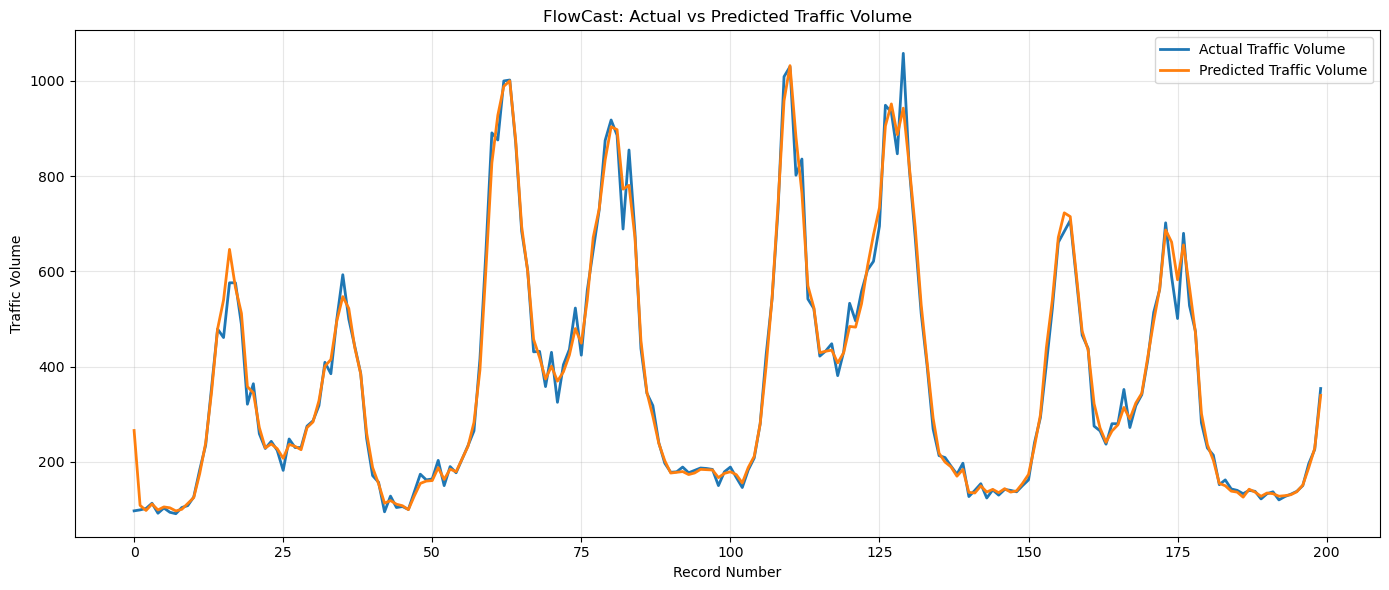

In [12]:
import matplotlib.pyplot as plt

# Plot a sample of the first 200 records
sample = comparison.head(200)

plt.figure(figsize=(14, 6))

plt.plot(
    sample["Actual_Traffic_Volume"].values,
    label="Actual Traffic Volume",
    linewidth=2
)

plt.plot(
    sample["Predicted_Traffic_Volume"].values,
    label="Predicted Traffic Volume",
    linewidth=2
)

plt.title("FlowCast: Actual vs Predicted Traffic Volume")
plt.xlabel("Record Number")
plt.ylabel("Traffic Volume")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Traffic Volume Model Evaluation — Summary

This notebook evaluates the FlowCast traffic-volume prediction model using actual and predicted traffic volumes. The model is assessed using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and Mean Absolute Percentage Error (MAPE). A comparison plot and error analysis help identify where predictions are accurate and where larger errors occur.

The current evaluation results are:

- MAE: 22.96
- RMSE: 37.51
- MAPE: 5.67%

These results are encouraging for the current dataset, but further validation is needed to confirm performance across different roads and time periods.

In [13]:


import os
import numpy as np
import pandas as pd

print("FlowCast traffic forecasting - final checks")
print("-" * 45)

print("Dataset rows:", len(df))
print("Number of model features:", len(model_features))
print("Number of predictions:", len(y_pred))
print("Predictions contain missing values:", pd.isna(y_pred).any())
print("Predictions contain infinite values:", np.isinf(y_pred).any())
print("Predictions are non-negative:", (np.asarray(y_pred) >= 0).all())

print("\nPrediction summary:")
print(pd.Series(y_pred, name="predicted_traffic_volume").describe().round(2))

print("\nNotebook checks completed.")

FlowCast traffic forecasting - final checks
---------------------------------------------
Dataset rows: 176701
Number of model features: 14
Number of predictions: 176701
Predictions contain missing values: False
Predictions contain infinite values: False
Predictions are non-negative: True

Prediction summary:
count    176701.00
mean        431.70
std         277.83
min          49.42
25%         196.46
50%         366.15
75%         601.48
max        1882.30
Name: predicted_traffic_volume, dtype: float64

Notebook checks completed.
